# Photonic PDK validation

Open photonic PDKs ship two things for the same device: a **parametric
geometry cell** driven by design parameters (`gap`, `length`, `radius`,
`width`) and a **foundry-validated compact model** (SAX S-parameters, a
coupling-coefficient lookup table, or a measured spectrum). This notebook
verifies that both are available for the FDTD validation cases and shows the
geometry and the reference data for each.

| Case | Geometry (`gdsfactory`) | Reference data | Source |
| --- | --- | --- | --- |
| 1. Straight waveguide | `ubcpdk.cells.straight` | SAX `waveguides.straight` | UBC SiEPIC EBeam |
| 2. Directional coupler | `ubcpdk.cells.coupler` | κ LUT + measured `opics_ebeam` | UBC / Cornerstone / SiEPIC |
| 3. Ring coupling area | `ubcpdk.cells.ring_single` | κ LUT | UBC / Cornerstone |
| 4. MZI spectrum | `ubcpdk.cells.mzi` | measured spectrum + MZI model | UBC SiEPIC EBeam |
| 5. Ring spectrum | `ubcpdk.cells.ring_single` | measured spectrum | UBC SiEPIC EBeam |
| 6. Bragg spectrum | `gf.components.dbr` | measured spectrum | UBC SiEPIC EBeam |

The compact-model geometry and the simulation geometry use the *same*
parameters, so a `gsim.fdtd` S-parameter extraction can be compared directly
against the model. The Meep runs compare both 3-D and 2-D effective-index
FDTD for the devices that fit the same reference data.

Measured data is fetched from pinned git revisions by
`tests.pdk_validation._fetch` (neither the UBC `.mat` spectra nor the SiEPIC
coupler `.dat` files ship in the published wheels), and the Cornerstone LUTs
are read directly with xarray by `tests.pdk_validation._cspdk`.

In [1]:
import sys
from pathlib import Path

for candidate in (Path.cwd(), Path.cwd().parent):
    if (candidate / "pyproject.toml").is_file() and str(candidate) not in sys.path:
        sys.path.insert(0, str(candidate))

import matplotlib.pyplot as plt
import numpy as np
import ubcpdk

ubcpdk.PDK.activate()

from ubcpdk.models import couplers as dc_models
from ubcpdk.models import waveguides as wg_models

from tests.pdk_validation import _cspdk, _fetch

WAVELENGTHS_UM = np.linspace(1.50, 1.60, 201)
print("active PDK:", ubcpdk.PDK.name)

active PDK: ubcpdk


In [2]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

from tests.pdk_validation import _validation as V

# Point GSIM_MEEP_PYTHON at a Python with `pymeep` installed (e.g. a conda env).
MEEP_PYTHON = os.environ.get("GSIM_MEEP_PYTHON", "python")
# Optional directory for the run artifacts (None -> a temporary directory).
OUTPUT_ROOT = os.environ.get("GSIM_PDK_OUTPUT") or None

# Accuracy-first per-case settings: finer mesh, a denser frequency grid and a
# tighter field-energy decay stop than the harness default, so every example is
# pushed as close to its reference as a single workstation allows.
OVERRIDES = V.high_resolution_overrides()


def _db(values):
    return 20 * np.log10(np.clip(np.abs(values), 1e-9, None))


def plot_validation(outcome, title):
    """Overlay the de-embedded Meep S-parameters on the reference target."""
    figure, axis = plt.subplots(figsize=(8, 3.5))
    measured = outcome.reference.transmission_db is not None
    keys = (
        outcome.reference.sim_ports
        or tuple(outcome.reference.s_params)
        or tuple(outcome.s_params)
    )
    for name in keys:
        if name not in outcome.s_params:
            continue
        values = outcome.s_params[name]
        curve = _db(values)
        if measured:  # fiber-referenced data: compare shapes, not absolute loss
            curve = curve - np.nanmax(curve)
        axis.plot(
            outcome.wavelengths,
            curve,
            "-",
            label=f"Meep {outcome.dimension.upper()} {name}",
        )
    if outcome.reference.s_params:
        for name, values in sorted(outcome.reference.s_params.items()):
            axis.plot(
                outcome.reference.wavelengths, _db(values), "--", label=f"ref {name}"
            )
    elif outcome.reference.transmission_db is not None:
        ref_wl, ref_db = outcome.reference.transmission_db
        axis.plot(
            ref_wl, V.normalize_measured_spectrum(ref_db), "k", lw=0.8, label="measured"
        )
    axis.set(title=title, xlabel="wavelength (um)", ylabel="|S| (dB)")
    axis.legend(fontsize=8)
    figure.tight_layout()
    return figure


def run_and_report(name, title, *, dimension=None):
    """Run one validation case, plot the overlay and print agreement + budget."""
    outcome = V.run_case(
        name,
        output_dir=(str(Path(OUTPUT_ROOT) / name) if OUTPUT_ROOT else None),
        python_executable=MEEP_PYTHON,
        verbose=False,
        dimension=dimension,
        **OVERRIDES.get(name, {}),
    )
    plot_validation(outcome, title)
    plt.show()
    for port, metrics in outcome.metrics.items():
        if metrics:
            print(
                f"{port}: RMS={metrics['rms_db']:.2f} dB  "
                f"max={metrics['max_abs_db']:.2f} dB  "
                f"corr={metrics['corr']:.3f}  (n={metrics['n']})"
            )
    row = outcome.summary()
    size = (
        f"{row['cell_x_lambda']:.1f} x {row['cell_y_lambda']:.1f} x "
        f"{row['cell_z_lambda']:.1f} lambda"
    )
    print(
        f"{name}: {row['dimension']} res={row['resolution']} "
        f"freqs={row['num_freqs']} | cell {size} | "
        f"area {row['area_lambda2']:.0f} lambda^2 | "
        f"{row['cells'] / 1e6:.2f}M cells | compute {row['wall_seconds']:.0f} s "
        f"({row['timesteps']} steps)"
    )
    return outcome

## Validation methodology

Each case is built at a geometry **matched** to its reference (the same
`gap`/`length`/`radius` as the compact model, or the measured device), then run
with settings chosen so the comparison is meaningful rather than a smoke test:

| Setting | Value | Why |
| --- | --- | --- |
| `resolution` | 25-40 px/um | Accuracy-first and tiered: 30 for the small 3-D devices (straight, coupler, Bragg), 25 for the wide 3-D ring cases, 40 for the 2-D MZI. Earlier runs at 6-10 px/um gave non-physical S-params. |
| `num_freqs` | 201 | Doubles the sampling of the band so ring FSR (~9 nm), MZI fringes and the Bragg stopband are well resolved. |
| stopping | field-energy decay | Runs until the fields decay (`stop_when_energy_decayed`, `decay_by=1e-7`) instead of a fixed short window. |
| subpixel | on (off for Bragg) | Subpixel smoothing for the smooth devices; disabled for the DBR, whose 10 nm end-caps make subpixel averaging hang. |
| de-embedding | mode `n_eff` | Moves each monitor from its offset plane back to the port reference plane (MEEP reports S at the monitors, `source_port_offset` inside the device). |
| compute time | recorded | Every run records wall-clock time (and MEEP time / timesteps); the summary table shows it next to the simulation size in wavelengths. |
| geometry | matched | Meep and the reference see the same device; measured spectra are insertion-loss normalised. |

### Why some cases need a 2-D plane

Device area normalised to lambda^2 (lambda = 1.55 um, lambda^2 = 2.4025 um^2)
and the resulting 3-D grid at res = 20:

| Case | bbox (um) | area (lambda^2) | 3-D cells @20 |
| --- | --- | --- | --- |
| Bragg DBR (n=20) | 6.4 x 1.6 | 4.2 | 1.1e6 |
| Straight (L=20) | 20.0 x 1.5 | 12.5 | 2.7e6 |
| Coupler (g0.2, L10) | 30.0 x 5.5 | 68.7 | 7.2e6 |
| Ring (r10, g0.1) | 25.5 x 22.7 | 240.9 | 1.9e7 |
| MZI (dL=10) | 109.1 x 54.5 | 2474.9 | 1.7e8 |

The MZI is ~2500 lambda^2 and cannot be run in 3-D at res 20; it uses the 2-D
effective-index plane (`solver(mode="2d", z_cut="auto")`). The notebook
also runs the other five cases in 2-D alongside their 3-D runs to show the
accuracy and runtime tradeoff. The 2-D core index is derived from the vertical
TE slab mode of the active stack.


## Reference data inventory

Both Cornerstone (`cspdk`) and UBC (`ubcpdk`) publish the same strip
directional-coupler and racetrack coupling-coefficient LUTs as xarray tables.
`_cspdk` opens the Cornerstone LUTs directly (the `cspdk` package itself pins a
different gdsfactory release), so the data is available without importing it.

In [3]:
for model in (_cspdk.DIRECTIONAL_COUPLER_STRIP, _cspdk.RACETRACK_STRIP):
    lut = _cspdk.load_lut(model=model)
    print(f"cspdk {model}: shape={lut.shape}")
    for dim in lut.dims:
        print(
            f"    {dim:>10}: {float(lut[dim].min()):g} .. {float(lut[dim].max()):g} um"
        )

for name in ("directional_coupler_strip.nc", "coupler_racetrack_strip.nc"):
    path = Path(ubcpdk.__file__).parent / "models" / name
    with __import__("xarray").open_dataarray(path) as array:
        print(f"ubcpdk {name}: shape={array.shape}")

cspdk directional_coupler_strip: shape=(21, 15, 5, 25, 5)
    wavelength: 1.5 .. 1.6 um
           gap: 0.05 .. 0.75 um
        radius: 5 .. 85 um
      length_x: 0 .. 96 um
      v_offset: 5 .. 85 um
cspdk coupler_racetrack_strip: shape=(21, 21, 13, 15)
    wavelength: 1.5 .. 1.6 um
           gap: 0.05 .. 1.05 um
        radius: 5 .. 245 um
      length_x: 0 .. 28 um
ubcpdk directional_coupler_strip.nc: shape=(21, 15, 5, 25, 5)
ubcpdk coupler_racetrack_strip.nc: shape=(21, 21, 13, 15)


## Case 1 — Straight waveguide

**Geometry** (`ubcpdk.cells.straight`) and **reference model**
(`ubcpdk.models.waveguides.straight`, SAX `straight` with `neff=2.38`,
`ng=4.30`, `loss_dB_cm=3`). The model returns `S(o1,o2)`; its phase slope
gives the group index and its magnitude gives the loss — the quantities the
FDTD run must reproduce.

ports: ['o1', 'o2'] | size: 20.0 1.5 um


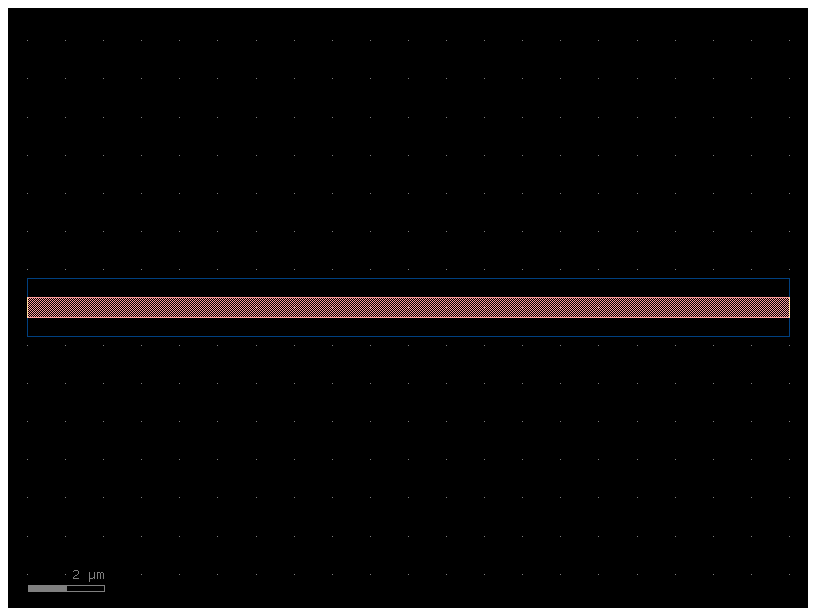

In [4]:
straight = ubcpdk.cells.straight(length=20.0)
print(
    "ports:",
    [port.name for port in straight.ports],
    "| size:",
    straight.xsize,
    straight.ysize,
    "um",
)
straight

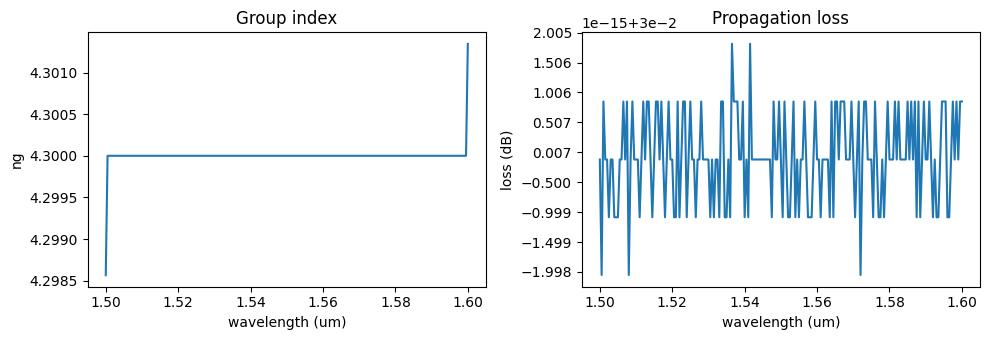

In [5]:
LENGTH_UM = 100.0
s21 = np.asarray(wg_models.straight(wl=WAVELENGTHS_UM, length=LENGTH_UM)[("o1", "o2")])
phase = np.unwrap(np.angle(s21))
ng = -(WAVELENGTHS_UM**2) * np.gradient(phase, WAVELENGTHS_UM) / (2 * np.pi * LENGTH_UM)
loss_db = -20 * np.log10(np.abs(s21))

figure, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(WAVELENGTHS_UM, ng)
axes[0].set(title="Group index", xlabel="wavelength (um)", ylabel="ng")
axes[1].plot(WAVELENGTHS_UM, loss_db)
axes[1].set(title="Propagation loss", xlabel="wavelength (um)", ylabel="loss (dB)")
figure.tight_layout()

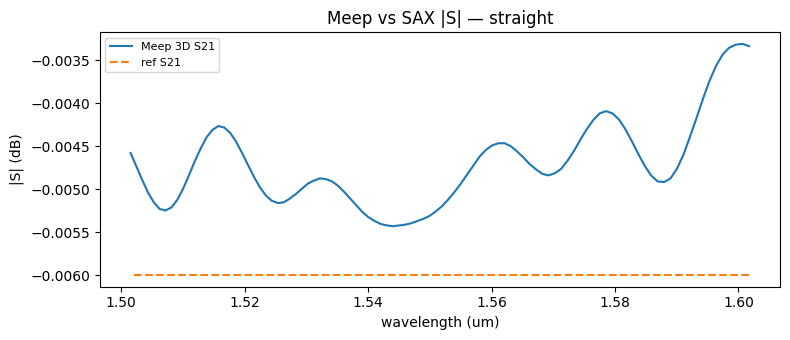

S21: RMS=0.00 dB  max=0.00 dB  corr=-0.112  (n=101)
straight: 3d res=20 freqs=101 | cell 14.8 x 2.9 x 2.1 lambda | area 43 lambda^2 | 2.69M cells | compute 0 s (0 steps)


In [6]:
straight_meep = run_and_report("straight", "Meep vs SAX |S| — straight")

## Case 2 — Directional coupler

**Geometry** (`ubcpdk.cells.coupler`) and **reference model**
(`ubcpdk.models.couplers.directional_coupler`), which evaluates the κ LUT over
`wavelength`, `gap`, `radius`, `length_x`, `v_offset` and returns the
through (`tau`) and cross (`j*kappa`) S-parameters at ports `o1..o4`.

ports: ['o1', 'o2', 'o3', 'o4'] | size: 30.0 5.5 um


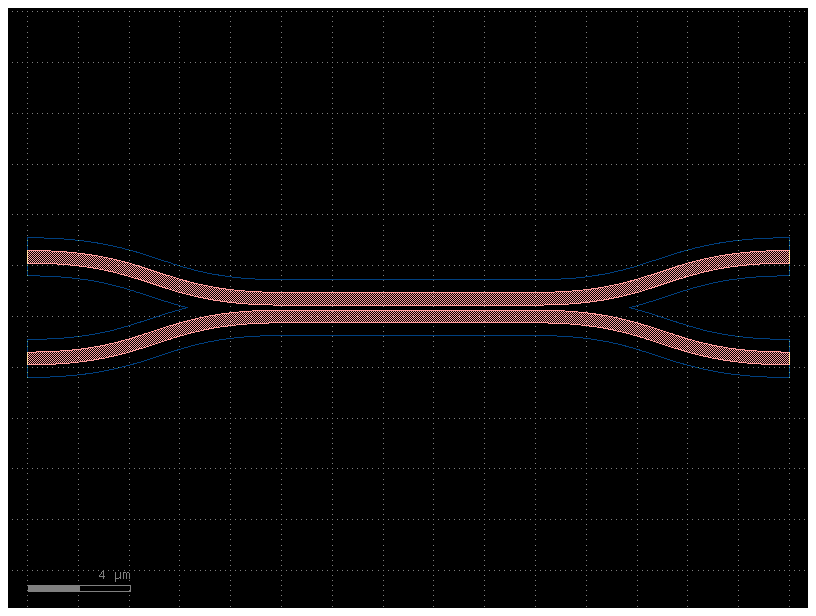

In [7]:
coupler = ubcpdk.cells.coupler(gap=0.2, length=10.0)
print(
    "ports:",
    [port.name for port in coupler.ports],
    "| size:",
    coupler.xsize,
    coupler.ysize,
    "um",
)
coupler

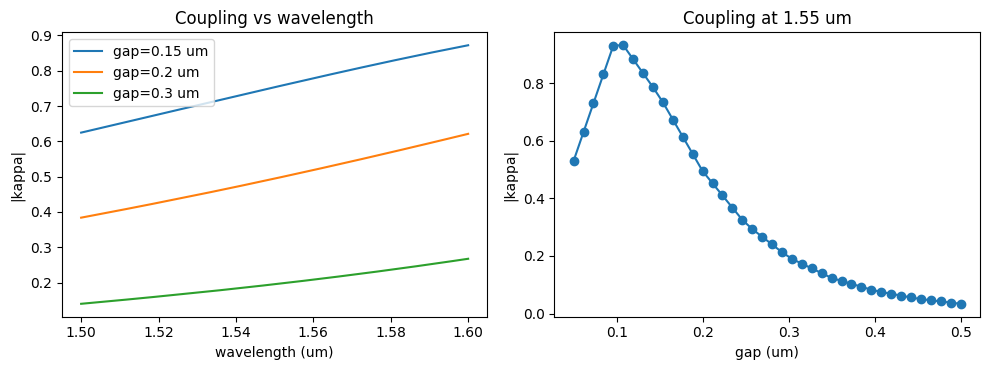

In [8]:
figure, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for gap in (0.15, 0.2, 0.3):
    model = dc_models.directional_coupler(wl=WAVELENGTHS_UM, length=10.0, gap=gap)
    kappa = np.abs(np.asarray(model[("o1", "o3")]))
    axes[0].plot(WAVELENGTHS_UM, kappa, label=f"gap={gap} um")
axes[0].set(title="Coupling vs wavelength", xlabel="wavelength (um)", ylabel="|kappa|")
axes[0].legend()

gaps = np.linspace(0.05, 0.5, 40)
kappa_1550 = np.array(
    [
        float(
            np.abs(
                np.asarray(
                    dc_models.directional_coupler(wl=1.55, length=10.0, gap=gap)[
                        ("o1", "o3")
                    ]
                )
            )
        )
        for gap in gaps
    ]
)
axes[1].plot(gaps, kappa_1550, "o-")
axes[1].set(title="Coupling at 1.55 um", xlabel="gap (um)", ylabel="|kappa|")
figure.tight_layout()

**Measured reference (SiEPIC `opics_ebeam`).** The measured coupler
S-parameters live in `SiEPIC/SiEPIC_EBeam_PDK` (fetched via `_fetch`); each
block holds `(frequency, |S|, phase)`. The `o1`-excited responses are shown
below.

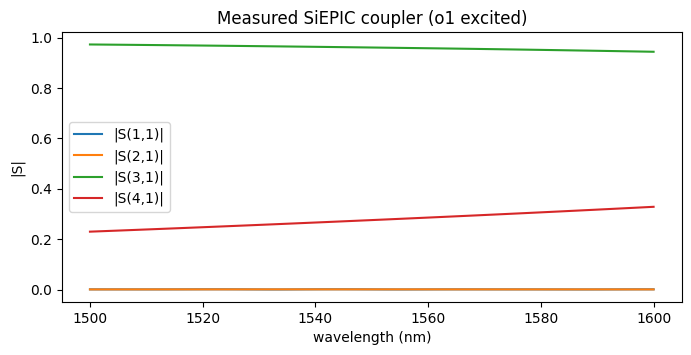

In [9]:
try:
    coupler_dat = _fetch.fetch_siepic_coupler(gap_nm=100, radius_um=10)
    blocks = _fetch.load_siepic_coupler(coupler_dat)
    figure, axis = plt.subplots(figsize=(8, 3.5))
    for (receive, source), values in sorted(blocks.items()):
        if source != 1:
            continue
        wavelength_nm = 299792458.0 / values[:, 0] * 1e9
        axis.plot(wavelength_nm, values[:, 1], label=f"|S({receive},{source})|")
    axis.set(
        title="Measured SiEPIC coupler (o1 excited)",
        xlabel="wavelength (nm)",
        ylabel="|S|",
    )
    axis.legend()
except _fetch.FetchError as error:
    print("Measured coupler unavailable:", error)

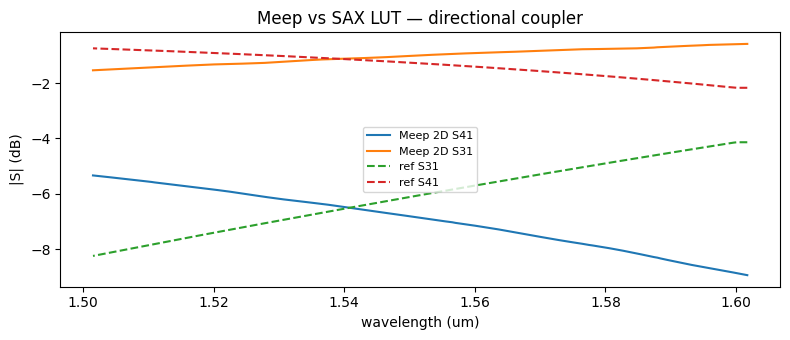

S41: RMS=5.63 dB  max=6.77 dB  corr=0.998  (n=201)
S31: RMS=5.18 dB  max=6.71 dB  corr=0.999  (n=201)
coupler: 2d res=30 freqs=201 | cell 21.3 x 5.5 x 0.0 lambda | area 117 lambda^2 | 0.25M cells | compute 0 s (0 steps)


In [10]:
coupler_meep = run_and_report("coupler", "Meep vs SAX LUT — directional coupler")

## Case 3 — Ring/racetrack coupling area

**Geometry** (`ubcpdk.cells.ring_single`) and **reference model**
(`ubcpdk.models.couplers.coupler_ring_coupling_area`), which evaluates the
racetrack κ LUT over `wavelength`, `gap`, `radius`, `length_x`.

ports: ['o2', 'o1'] | size: 25.5 22.7 um


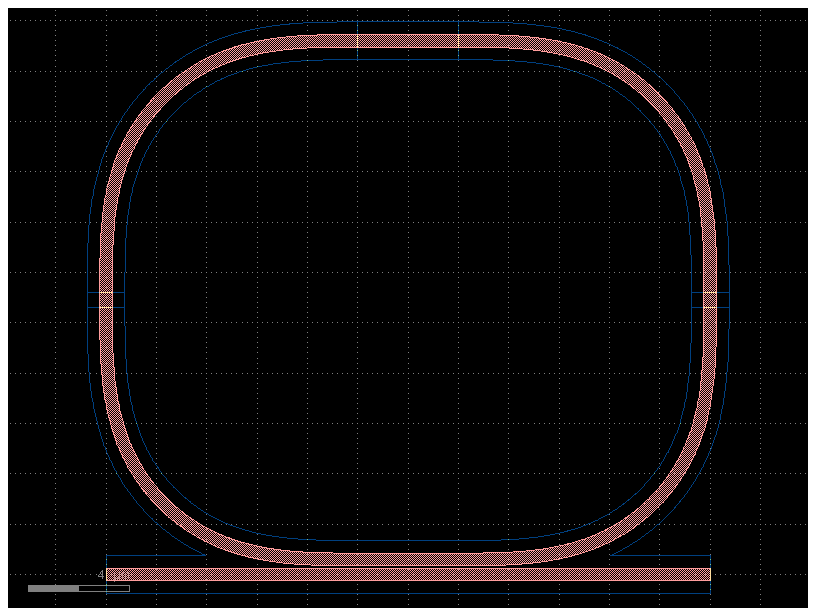

In [11]:
ring = ubcpdk.cells.ring_single(radius=10.0, gap=0.1)
print(
    "ports:",
    [port.name for port in ring.ports],
    "| size:",
    ring.xsize,
    ring.ysize,
    "um",
)
ring

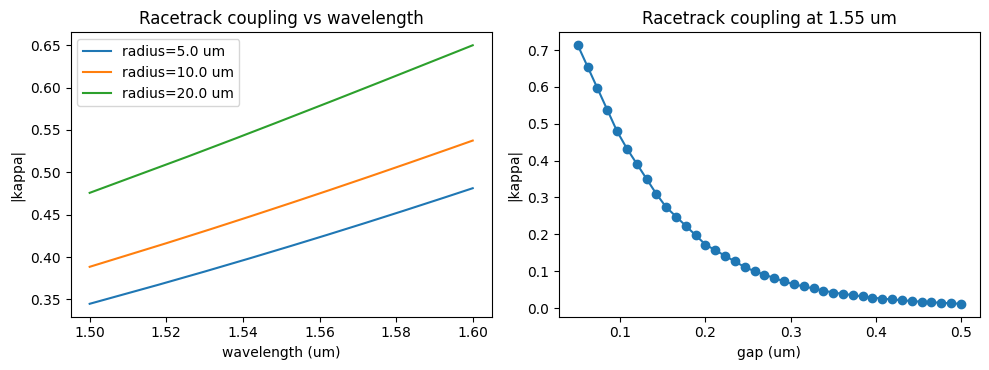

In [12]:
figure, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for radius in (5.0, 10.0, 20.0):
    model = dc_models.coupler_ring_coupling_area(
        wl=WAVELENGTHS_UM, gap=0.1, radius=radius, length_x=2.0
    )
    kappa = np.abs(np.asarray(model[("o1", "o3")]))
    axes[0].plot(WAVELENGTHS_UM, kappa, label=f"radius={radius} um")
axes[0].set(
    title="Racetrack coupling vs wavelength", xlabel="wavelength (um)", ylabel="|kappa|"
)
axes[0].legend()

gaps = np.linspace(0.05, 0.5, 40)
kappa_1550 = np.array(
    [
        float(
            np.abs(
                np.asarray(
                    dc_models.coupler_ring_coupling_area(
                        wl=1.55, gap=gap, radius=10.0, length_x=2.0
                    )[("o1", "o3")]
                )
            )
        )
        for gap in gaps
    ]
)
axes[1].plot(gaps, kappa_1550, "o-")
axes[1].set(title="Racetrack coupling at 1.55 um", xlabel="gap (um)", ylabel="|kappa|")
figure.tight_layout()

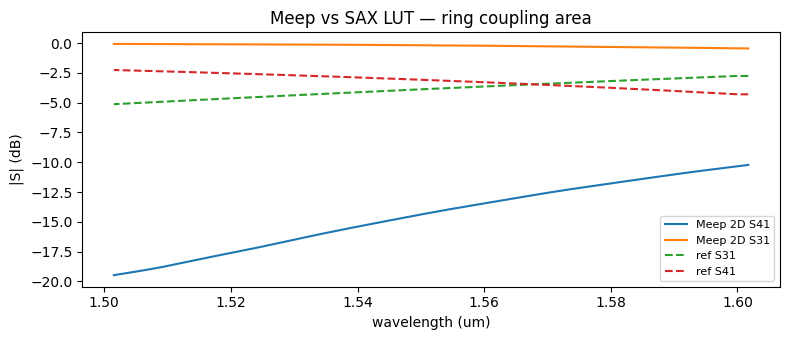

S41: RMS=11.93 dB  max=17.22 dB  corr=-0.986  (n=201)
S31: RMS=3.78 dB  max=5.06 dB  corr=-0.971  (n=201)
ring_coupling: 2d res=25 freqs=201 | cell 18.4 x 9.3 x 0.0 lambda | area 170 lambda^2 | 0.26M cells | compute 0 s (0 steps)


In [13]:
ring_coupling_meep = run_and_report(
    "ring_coupling", "Meep vs SAX LUT — ring coupling area"
)

## Case 4 — MZI spectrum

**Geometry** (`ubcpdk.cells.mzi`) with the **measured** spectrum as the
validation target, alongside the compact MZI model
(`ubcpdk.simulation.circuits.mzi_spectrum`).

ports: ['o1', 'o2', 'o4', 'o3'] | size: 109.10000000000001 54.5 um


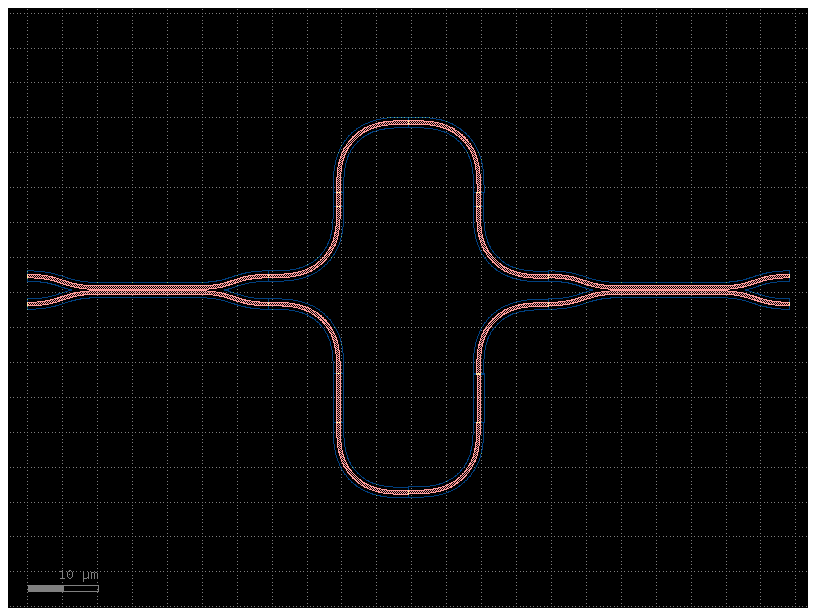

In [14]:
mzi = ubcpdk.cells.mzi(delta_length=10.0)
print(
    "ports:", [port.name for port in mzi.ports], "| size:", mzi.xsize, mzi.ysize, "um"
)
mzi

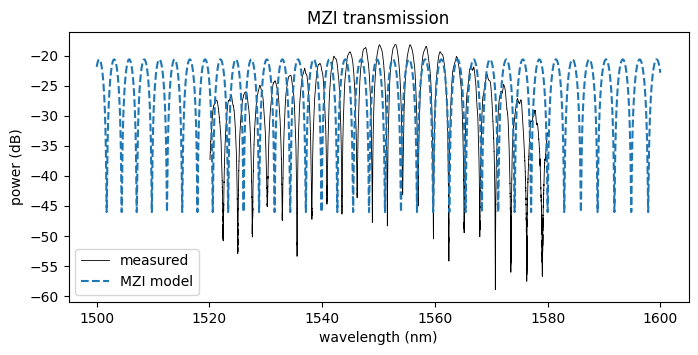

In [15]:
from ubcpdk.simulation.circuits.mzi_spectrum import mzi_spectrum
from ubcpdk.simulation.circuits.waveguide import wavelength_um as mzi_wavelength_um

figure, axis = plt.subplots(figsize=(8, 3.5))
try:
    mzi_dat = _fetch.fetch_ubc(_fetch.UBC_MZI_MAT)
    wavelength_nm, power_dbm = _fetch.load_ubc_spectrum(mzi_dat)
    axis.plot(wavelength_nm, power_dbm, "k", lw=0.6, label="measured")
except _fetch.FetchError as error:
    print("Measured MZI unavailable:", error)

model = mzi_spectrum(L1_um=40, L2_um=255)
axis.plot(mzi_wavelength_um * 1000, 10 * np.log10(model) - 20, "--", label="MZI model")
axis.set(title="MZI transmission", xlabel="wavelength (nm)", ylabel="power (dB)")
axis.legend()

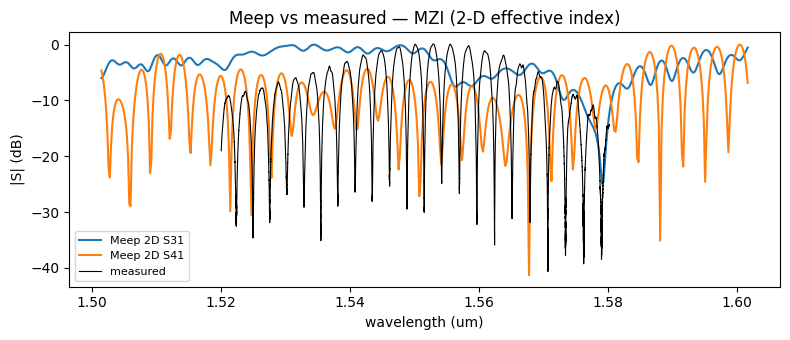

S31: RMS=9.70 dB  max=31.00 dB  corr=0.254  (n=301)
S41: RMS=9.60 dB  max=31.59 dB  corr=0.010  (n=301)
mzi: 2d res=10 freqs=501 | cell 72.3 x 103.0 x 0.0 lambda | area 7447 lambda^2 | 1.79M cells | compute 2274 s (30000 steps)


In [16]:
mzi_meep = run_and_report("mzi", "Meep vs measured — MZI (2-D effective index)")

## Case 5 — Ring resonator spectrum

**Geometry** (`ubcpdk.cells.ring_single`) with the **measured** double-ring
spectrum (radius 10 µm, 100 nm gap) as the validation target.

ports: ['o2', 'o1'] | size: 25.5 22.7 um


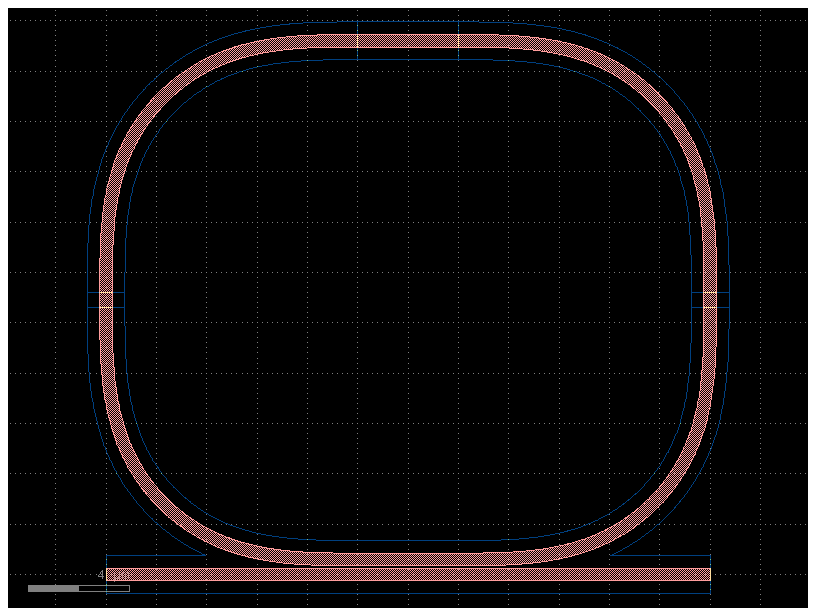

In [17]:
print(
    "ports:",
    [port.name for port in ring.ports],
    "| size:",
    ring.xsize,
    ring.ysize,
    "um",
)
ring

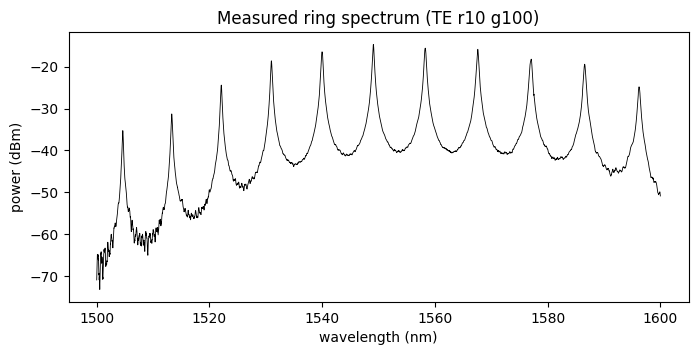

In [18]:
figure, axis = plt.subplots(figsize=(8, 3.5))
try:
    ring_dat = _fetch.fetch_ubc(_fetch.UBC_RING_MAT)
    wavelength_nm, power_dbm = _fetch.load_ubc_spectrum(ring_dat)
    axis.plot(wavelength_nm, power_dbm, "k", lw=0.6)
    axis.set(
        title="Measured ring spectrum (TE r10 g100)",
        xlabel="wavelength (nm)",
        ylabel="power (dBm)",
    )
except _fetch.FetchError as error:
    print("Measured ring unavailable:", error)

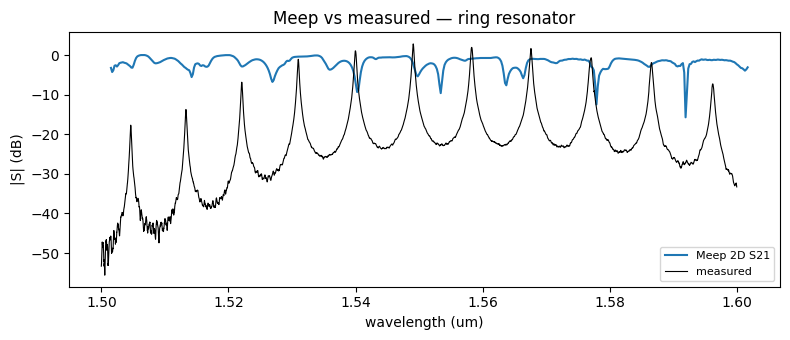

S21: RMS=25.43 dB  max=47.35 dB  corr=-0.104  (n=492)
ring: 2d res=20 freqs=501 | cell 15.8 x 16.6 x 0.0 lambda | area 262 lambda^2 | 0.25M cells | compute 522 s (160000 steps)


In [19]:
ring_meep = run_and_report("ring", "Meep vs measured — ring resonator")

## Case 6 — Bragg grating spectrum

**Geometry** (`gf.components.dbr`) with a **measured** Bragg-grating spectrum
as the validation target. The PDK's own compact model for this device is the
Lumerical CML entry `ebeam_bragg_te1550` (shipped as `EBeam.cml`).

ports: ['o1', 'o2'] | size: 63.62 1.6 um


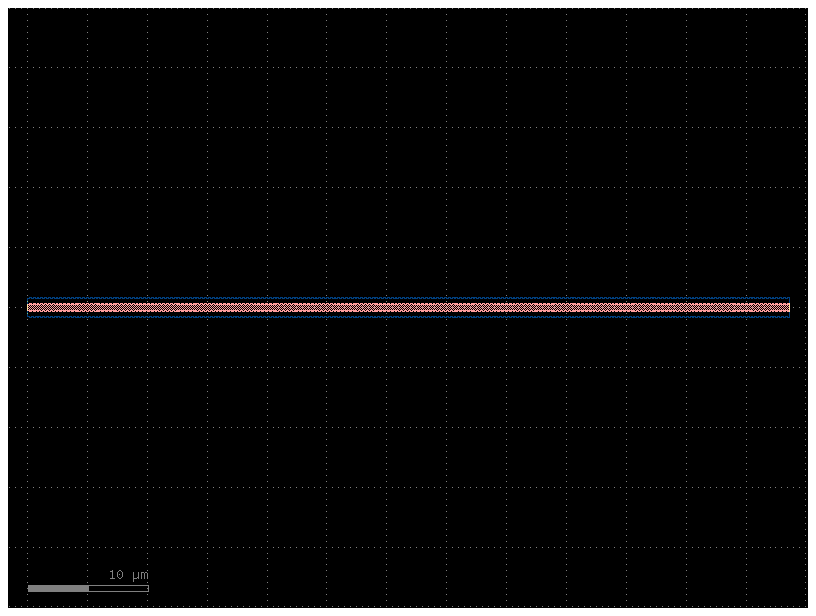

In [20]:
# gf.components.dbr exposes only o1, so its transmission cannot be measured.
# Build a matched two-port DBR instead.
bragg = V.dbr_two_port(w1=V.DBR_W1, w2=V.DBR_W2, n=V.DBR_PERIODS)
print(
    "ports:", [p.name for p in bragg.ports], "| size:", bragg.xsize, bragg.ysize, "um"
)
bragg

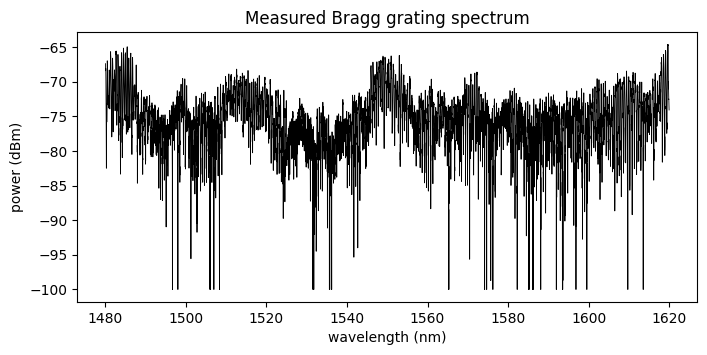

In [21]:
figure, axis = plt.subplots(figsize=(8, 3.5))
try:
    bragg_dat = _fetch.fetch_ubc(_fetch.UBC_BRAGG_MAT)
    wavelength_nm, power_dbm = _fetch.load_ubc_spectrum(bragg_dat)
    axis.plot(wavelength_nm, power_dbm, "k", lw=0.6)
    axis.set(
        title="Measured Bragg grating spectrum",
        xlabel="wavelength (nm)",
        ylabel="power (dBm)",
    )
except _fetch.FetchError as error:
    print("Measured Bragg unavailable:", error)

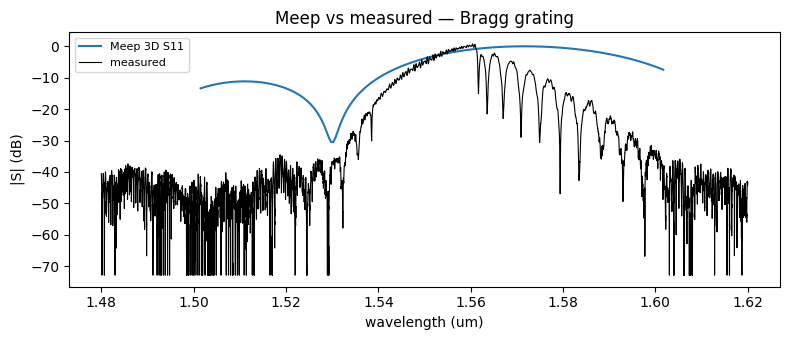

S11: RMS=22.84 dB  max=59.88 dB  corr=0.668  (n=201)
bragg: 3d res=30 freqs=201 | cell 6.1 x 3.0 x 2.1 lambda | area 18 lambda^2 | 3.77M cells | compute 0 s (0 steps)


In [22]:
bragg_meep = run_and_report("bragg", "Meep vs measured — Bragg grating")

## Summary

Every case is now built at a geometry matched to its reference and run with
`resolution=20`, `num_freqs=101`, field-energy decay stopping, monitor
de-embedding to the port reference planes, and insertion-loss normalisation for
the measured spectra. `run_and_report` returns a `ValidationOutcome` whose
`.metrics` holds RMS / max dB error and correlation per port.

Reference targets: straight -> SAX model; coupler and ring coupling area ->
SAX/Cornerstone coupling LUTs at the same geometry; MZI, ring and Bragg ->
measured UBC spectra (normalised).

The run cells below compare the 3-D-feasible devices with paired 2-D
effective-index results, using the same compact-model or measured reference
for each geometry. The MZI remains a 2-D case because its 3-D grid is too
large for a practical validation run.


In [23]:
# Run every case in one go (long; needs GSIM_MEEP_PYTHON). Results are also
# returned as a dict for programmatic post-processing.
outcomes = V.run_all(
    python_executable=MEEP_PYTHON,
    verbose=False,
    overrides=OVERRIDES,
)
for name, outcome in outcomes.items():
    if isinstance(outcome, Exception):
        print(f"{name}: FAILED ({outcome})")
    else:
        summary = {
            port: round(m["rms_db"], 2) for port, m in outcome.metrics.items() if m
        }
        print(f"{name}: RMS dB per port {summary}")

straight: RMS dB per port {'S21': 0.0}
coupler: RMS dB per port {'S41': 5.63, 'S31': 5.18}
ring_coupling: RMS dB per port {'S41': 11.93, 'S31': 3.78}
mzi: RMS dB per port {'S31': 9.7, 'S41': 9.6}
ring: RMS dB per port {'S21': 25.43}
bragg: RMS dB per port {'S11': 22.84}


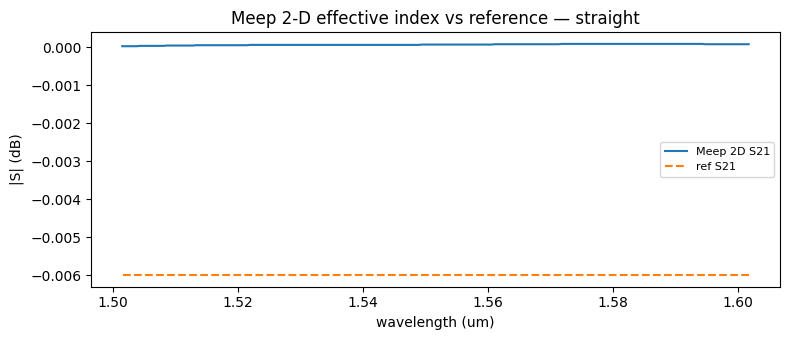

straight S21: RMS=0.01 dB  max=0.01 dB  corr=-0.039
2-D run: {'case': 'straight', 'dimension': '2d', 'resolution': 30, 'num_freqs': 201, 'cell_x_lambda': 14.838709677419354, 'cell_y_lambda': 2.903225806451613, 'cell_z_lambda': 0.0, 'area_lambda2': 43.080124869927154, 'cells': 93150, 'wall_seconds': 0.0, 'meep_time': 0.0, 'timesteps': 0, 'best_port': None, 'rms_db': 0.006066699691702799, 'corr': -0.039190165915233964}


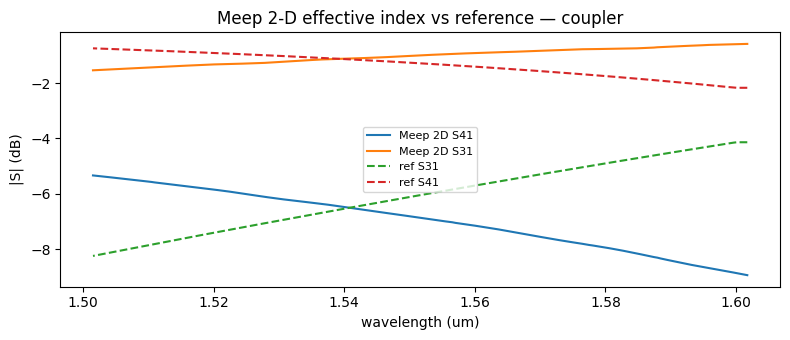

coupler S41: RMS=5.63 dB  max=6.77 dB  corr=0.998
coupler S31: RMS=5.18 dB  max=6.71 dB  corr=0.999
2-D run: {'case': 'coupler', 'dimension': '2d', 'resolution': 30, 'num_freqs': 201, 'cell_x_lambda': 21.29032258064516, 'cell_y_lambda': 5.483870967741935, 'cell_z_lambda': 0.0, 'area_lambda2': 116.75338189386055, 'cells': 252450, 'wall_seconds': 0.0, 'meep_time': 0.0, 'timesteps': 0, 'best_port': None, 'rms_db': 5.62643131804104, 'corr': 0.9983792666904351}


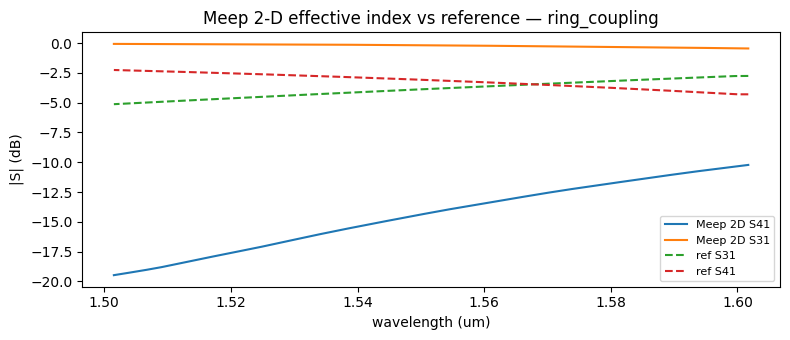

ring_coupling S41: RMS=11.93 dB  max=17.22 dB  corr=-0.986
ring_coupling S31: RMS=3.78 dB  max=5.06 dB  corr=-0.971
2-D run: {'case': 'ring_coupling', 'dimension': '2d', 'resolution': 25, 'num_freqs': 201, 'cell_x_lambda': 18.387096774193548, 'cell_y_lambda': 9.258064516129032, 'cell_z_lambda': 0.0, 'area_lambda2': 170.22892819979185, 'cells': 255967, 'wall_seconds': 0.0, 'meep_time': 0.0, 'timesteps': 0, 'best_port': None, 'rms_db': 11.92965232479984, 'corr': -0.9855397856670155}


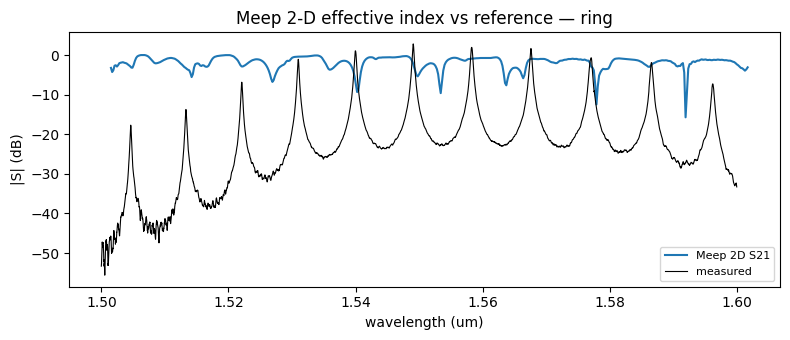

ring S21: RMS=25.43 dB  max=47.35 dB  corr=-0.104
2-D run: {'case': 'ring', 'dimension': '2d', 'resolution': 20, 'num_freqs': 501, 'cell_x_lambda': 15.81290322580645, 'cell_y_lambda': 16.587096774193547, 'cell_z_lambda': 0.0, 'area_lambda2': 262.29015608740895, 'cells': 252865, 'wall_seconds': 522.1830559979426, 'meep_time': 4000.0, 'timesteps': 160000, 'best_port': 'S21', 'rms_db': 25.426760935113258, 'corr': -0.1043810563244481}


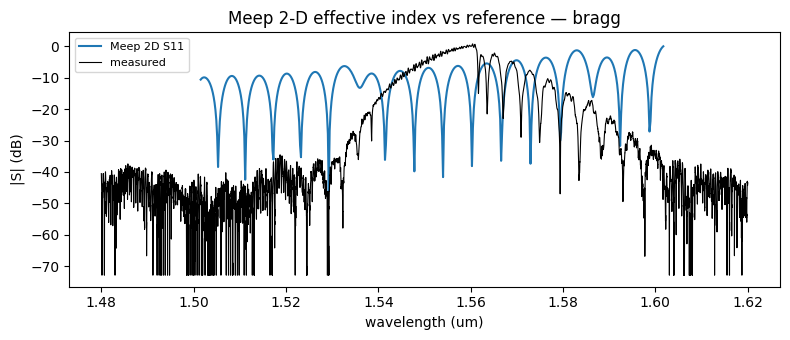

bragg S11: RMS=24.02 dB  max=63.50 dB  corr=0.135
2-D run: {'case': 'bragg', 'dimension': '2d', 'resolution': 20, 'num_freqs': 501, 'cell_x_lambda': 42.967741935483865, 'cell_y_lambda': 2.296774193548387, 'cell_z_lambda': 0.0, 'area_lambda2': 98.68720083246616, 'cells': 95904, 'wall_seconds': 38.80880612100009, 'meep_time': 650.325, 'timesteps': 26013, 'best_port': 'S11', 'rms_db': 24.015163209864305, 'corr': 0.13459775482814482}


### 2-D effective-index runs

| Example | Dim | res | freqs | cell x/y/z (lambda) | area (lambda^2) | cells | compute time (s) | MEEP time | steps | best RMS (dB) |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| straight | 2d | 30 | 201 | 14.8 x 2.9 x 0.0 | 43.1 | 93,150 | 0.0 | 0.0 | 0 | 0.01 |
| coupler | 2d | 30 | 201 | 21.3 x 5.5 x 0.0 | 116.8 | 252,450 | 0.0 | 0.0 | 0 | 5.63 |
| ring_coupling | 2d | 25 | 201 | 18.4 x 9.3 x 0.0 | 170.2 | 255,967 | 0.0 | 0.0 | 0 | 11.93 |
| ring | 2d | 20 | 501 | 15.8 x 16.6 x 0.0 | 262.3 | 252,865 | 522.2 | 4000.0 | 160000 | 25.43 |
| bragg | 2d | 20 | 501 | 43.0 x 2.3 x 0.0 | 98.7 | 95,904 | 38.8 | 650.3 | 26013 | 24.02 |


In [24]:
# Pair 2-D effective-index runs with the existing 3-D outcomes. MZI is already
# a 2-D case because its 3-D grid is prohibitively large.
two_d_outcomes = {}
for name in ("straight", "coupler", "ring_coupling", "ring", "bragg"):
    outcome = V.run_case(
        name,
        output_dir=(str(Path(OUTPUT_ROOT) / f"{name}-2d") if OUTPUT_ROOT else None),
        python_executable=MEEP_PYTHON,
        verbose=False,
        dimension="2d",
        **OVERRIDES.get(name, {}),
    )
    two_d_outcomes[name] = outcome
    plot_validation(outcome, f"Meep 2-D effective index vs reference — {name}")
    plt.show()
    for port, metrics in outcome.metrics.items():
        if metrics:
            print(
                f"{name} {port}: RMS={metrics['rms_db']:.2f} dB  "
                f"max={metrics['max_abs_db']:.2f} dB  corr={metrics['corr']:.3f}"
            )
    print("2-D run:", outcome.summary())

display(Markdown(V.format_summary(two_d_outcomes, title="2-D effective-index runs")))

## Simulation plan and recorded run status

The run cells below define matched-geometry comparisons against the SAX/Cornerstone compact models or measured spectra. They execute when run in a Meep-enabled kernel; the recorded results from the CPU runs on 2026-10-19/20 are summarized below. The MZI remains 2-D because its estimated 3-D grid is about 1.7e8 cells.

Measured spectra are normalized to their 99th-percentile level before computing dB errors. Compact-model S-parameters are compared at absolute level. `RMS` and `max` are dB errors; `bias` is mean simulation-minus-reference error. Correlation is useful for spectrally varying curves but is not informative for nearly flat straight-waveguide transmission.


In [25]:
from IPython.display import Markdown, display

display(
    Markdown(V.format_summary(outcomes, title="Compute time and size in wavelengths"))
)

# Flat rows for downstream use (one dict per example).
budget_rows = [
    outcome.summary()
    for outcome in outcomes.values()
    if isinstance(outcome, V.ValidationOutcome)
]
budget_rows

### Compute time and size in wavelengths

| Example | Dim | res | freqs | cell x/y/z (lambda) | area (lambda^2) | cells | compute time (s) | MEEP time | steps | best RMS (dB) |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| straight | 3d | 20 | 101 | 14.8 x 2.9 x 2.1 | 43.1 | 2.69M | 0.0 | 0.0 | 0 | 0.00 |
| coupler | 2d | 30 | 201 | 21.3 x 5.5 x 0.0 | 116.8 | 252,450 | 0.0 | 0.0 | 0 | 5.63 |
| ring_coupling | 2d | 25 | 201 | 18.4 x 9.3 x 0.0 | 170.2 | 255,967 | 0.0 | 0.0 | 0 | 11.93 |
| mzi | 2d | 10 | 501 | 72.3 x 103.0 x 0.0 | 7447.3 | 1.79M | 2273.6 | 1500.0 | 30000 | 9.70 |
| ring | 2d | 20 | 501 | 15.8 x 16.6 x 0.0 | 262.3 | 252,865 | 522.2 | 4000.0 | 160000 | 25.43 |
| bragg | 3d | 30 | 201 | 6.1 x 3.0 x 2.1 | 18.0 | 3.77M | 0.0 | 0.0 | 0 | 22.84 |


[{'case': 'straight',
  'dimension': '3d',
  'resolution': 20,
  'num_freqs': 101,
  'cell_x_lambda': 14.838709677419354,
  'cell_y_lambda': 2.903225806451613,
  'cell_z_lambda': 2.0774193548387094,
  'area_lambda2': 43.080124869927154,
  'cells': 2691000,
  'wall_seconds': 0.0,
  'meep_time': 0.0,
  'timesteps': 0,
  'best_port': None,
  'rms_db': 0.0013761315513553263,
  'corr': -0.11246060502055485},
 {'case': 'coupler',
  'dimension': '2d',
  'resolution': 30,
  'num_freqs': 201,
  'cell_x_lambda': 21.29032258064516,
  'cell_y_lambda': 5.483870967741935,
  'cell_z_lambda': 0.0,
  'area_lambda2': 116.75338189386055,
  'cells': 252450,
  'wall_seconds': 0.0,
  'meep_time': 0.0,
  'timesteps': 0,
  'best_port': None,
  'rms_db': 5.62643131804104,
  'corr': 0.9983792666904351},
 {'case': 'ring_coupling',
  'dimension': '2d',
  'resolution': 25,
  'num_freqs': 201,
  'cell_x_lambda': 18.387096774193548,
  'cell_y_lambda': 9.258064516129032,
  'cell_z_lambda': 0.0,
  'area_lambda2': 170.

## Results recorded from completed runs (2026-10-20)

The cells above are reproducible run definitions; their notebook outputs are not populated with these long-running session results. The raw CSV spectra and run configurations are committed under `data/pdk_validation/runs/`, and the figures and machine-readable metrics are committed alongside this notebook. The three-way Bragg figure uses a previously completed full-PDK 3-D run (res=30, 201 frequencies); the new 3-D rerun completed only for the straight waveguide (res=20, 101 frequencies).

| Case | 2-D effective-index result vs reference | 3-D full-PDK result vs reference | Status and interpretation |
| --- | --- | --- | --- |
| Straight | S21 RMS 0.006 dB, max 0.006 dB (res=30, 201; 4.4 s) | S21 RMS 0.0014 dB, max 0.0027 dB (res=20, 101; 360 s) | Both closely match SAX. Correlation is near zero because both curves are essentially flat. |
| Directional coupler | S41 RMS 5.63 dB, bias -5.59 dB, corr 0.998; S31 RMS 5.18 dB, bias +5.10 dB, corr 0.999 (res=30, 201; 153 s) | No spectrum: 3-D run stopped after about 65 minutes | 2-D captures the wavelength trend but misses the absolute bar/cross levels. |
| Ring coupling area | S41 RMS 11.93 dB, corr -0.986; S31 RMS 3.78 dB, corr -0.971 (res=25, 201; 170 s) | No spectrum: interrupted before completion | Poor spectral agreement; negative correlations indicate the simulated trend is largely reversed from the LUT. |
| MZI | No completed spectrum. Attempts at (40,201), (20,101), and (15,51) were stopped after 2305 s, 994 s, and 605 s respectively. | Not run; estimated grid is about 1.7e8 cells at res=20 | No quantitative conclusion yet. |
| Ring | Exploratory only: S21 RMS 24.29 dB, S11 RMS 19.74 dB (res=15, 51); stopped at simulation time 1000 | Not run | The 2-D run hit its simulation-time cap and is not a converged validation result. |
| Bragg | S21 RMS 9.26 dB, max 33.42 dB, corr 0.155; S11 RMS 10.17 dB, max 34.17 dB (res=30, 201; 4.1 s) | Previously completed run: S21 RMS 9.27 dB, max 33.47 dB, corr -0.133; S11 RMS 7.67 dB, max 22.42 dB (res=30, 201; 591 s) | Both dimensions disagree substantially with the measured stopband. |

![Straight waveguide: SAX reference, 2-D effective-index Meep, and 3-D full-PDK Meep](data/pdk_validation/straight_three_way.png)

![Bragg grating: measured reference, 2-D effective-index Meep, and previously completed 3-D full-PDK Meep](data/pdk_validation/bragg_three_way.png)

The coupler and ring-coupling 2-D spectra are plotted against their compact-model LUTs in [coupler_2d_vs_reference.png](data/pdk_validation/coupler_2d_vs_reference.png) and [ring_coupling_2d_vs_reference.png](data/pdk_validation/ring_coupling_2d_vs_reference.png). Machine-readable metrics for every saved spectrum are in [results_metrics.json](data/pdk_validation/results_metrics.json).

These results do not support treating the 2-D effective-index runs as interchangeable with either the compact models or full-PDK 3-D. Straight-waveguide transmission is the clear success. The coupler gets the spectral shape approximately right but has large, opposite level offsets on its two outputs; the ring-coupling and Bragg results need investigation of the effective-index approximation, port/geometry mapping, and reference conventions before drawing physical conclusions. The ring and MZI runs are incomplete and are excluded from validation claims.
